# Phase 1: Data Quality Audit, Deduplication & Validation
**Bài toán:** Dự đoán khách hàng đóng thẻ tín dụng (`churn_3m`) tại thời điểm snapshot `30/06/2026`.
**Mục tiêu notebook:**
1. **Schema Audit:** Kiểm tra 24 cột dữ liệu thô, kiểu dữ liệu, các cột hằng số (`bank_code`, `currency`).
2. **Deduplication:** Xác minh và loại bỏ chính xác 120 dòng trùng lặp hoàn toàn, bảo toàn 12.000 khách hàng sạch.
3. **Target Distribution:** Đánh giá độ mất cân bằng lớp của `churn_3m` (11.708%).
4. **Missingness Audit:** Thống kê tỷ lệ khuyết thiếu cho 10 cột có dữ liệu null.
5. **Categorical Normalization:** Chuẩn hóa alias, viết hoa/thường, khoảng trắng (`gender`, `province`, `occupation`, `salary_via_bank`, `last_contact_channel`).
6. **Outliers & Unit Mismatch:** Phát hiện và sửa lỗi lệch đơn vị tiền tệ (`income_month`, `credit_limit`), xử lý sentinel `age=999`.
7. **Date & Snapshot Audit:** Phân tích 3 định dạng của `open_date`, kiểm định không có rò rỉ dữ liệu sau ngày snapshot `30/06/2026`.

In [1]:
import sys
from pathlib import Path

# Thêm root folder vào sys.path để import từ src
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import TRAIN_RAW_PATH, SNAPSHOT_DATE, TARGET_COL, ID_COL
from src.data_validation import (
    audit_schema,
    check_and_remove_duplicates,
    validate_target,
    audit_missing_values,
    audit_categories,
    audit_outliers_and_sentinels,
    audit_dates,
)
from src.preprocessing import clean_raw_dataframe, standardize_monetary_units, parse_open_date

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## 1. Tải dữ liệu thô & Kiểm tra Schema

In [2]:
df_raw = pd.read_csv(TRAIN_RAW_PATH)
schema_info = audit_schema(df_raw, is_train=True)
print(f"Kích thước tập thô: {schema_info['total_rows']} dòng x {schema_info['total_columns']} cột")
print(f"Đầy đủ cột bắt buộc: {schema_info['all_required_cols_present']}")
df_raw.head(3)

Kích thước tập thô: 12120 dòng x 24 cột
Đầy đủ cột bắt buộc: True


,customer_id,bank_code,age,gender,province,occupation,income_month,card_type,open_date,credit_limit,annual_fee_waived,utilization_6m,txn_count_3m,txn_amount_3m,spend_change_pct,app_logins_30d,complaints_12m,late_payments_12m,salary_via_bank,other_bank_cards,promo_ended_60d,last_contact_channel,currency,churn_3m
0,CUSTI3FNUD,VB01,48.0,F,Hải Dương,self_employed,25.1,Gold,2026-04-09,55.0,1,0.507,22,20.44,-23.5,2.0,0,0,N,1.0,0,app,vnd,1
1,CUSOOYRASU,VB01,47.0,M,Hà Nội,Salaried,NaN,Classic,06/01/2024,30.0,1,0.305,16,22.63,-27.7,4.0,0,0,Y,1.0,0,app,VND,0
2,CUSQTUBJRJ,VB01,38.0,M,Long An,other,8.5,Cashback,02/08/2022,15.0,0,0.107,18,11.06,-20.7,8.0,0,0,N,0.0,1,none,VND,0


## 2. Kiểm tra và loại bỏ 120 dòng trùng lặp hoàn toàn (Deduplication)

In [3]:
df_clean, dedup_stats = check_and_remove_duplicates(df_raw)
print("Kết quả Deduplication:")
for k, v in dedup_stats.items():
    print(f"  - {k}: {v}")

assert len(df_clean) == 12000, f"Expected 12000 clean rows, got {len(df_clean)}"
assert df_clean[ID_COL].nunique() == 12000, "Số customer_id duy nhất phải bằng 12000"

Kết quả Deduplication:
  - raw_rows: 12120
  - duplicate_rows_removed: 120
  - clean_rows: 12000
  - unique_customer_ids: 12000
  - remaining_id_duplicates: 0
  - is_id_unique: True


## 3. Phân phối Target `churn_3m`

Tỷ lệ Churn sau dedup: 11.708%
Số lượng khách hàng mỗi lớp: {'0': 10595, '1': 1405}


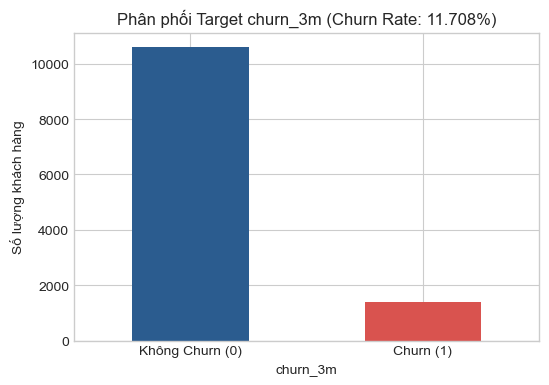

In [4]:
target_info = validate_target(df_clean)
print(f"Tỷ lệ Churn sau dedup: {target_info['churn_pct_str']}")
print(f"Số lượng khách hàng mỗi lớp: {target_info['value_counts']}")

fig, ax = plt.subplots(figsize=(6, 4))
df_clean[TARGET_COL].value_counts().plot(kind='bar', color=['#2b5c8f', '#d9534f'], ax=ax)
ax.set_title(f"Phân phối Target churn_3m (Churn Rate: {target_info['churn_pct_str']})")
ax.set_xticklabels(['Không Churn (0)', 'Churn (1)'], rotation=0)
plt.ylabel("Số lượng khách hàng")
plt.show()

## 4. Kiểm tra Giá trị Khuyết thiếu (Missingness Audit)

Danh sách cột bị khuyết thiếu:


,missing_count,missing_pct
other_bank_cards,2446,20.38
income_month,1547,12.89
app_logins_30d,1504,12.53
salary_via_bank,712,5.93
occupation,608,5.07
last_contact_channel,508,4.23
age,388,3.23
gender,229,1.91
province,197,1.64
open_date,78,0.65


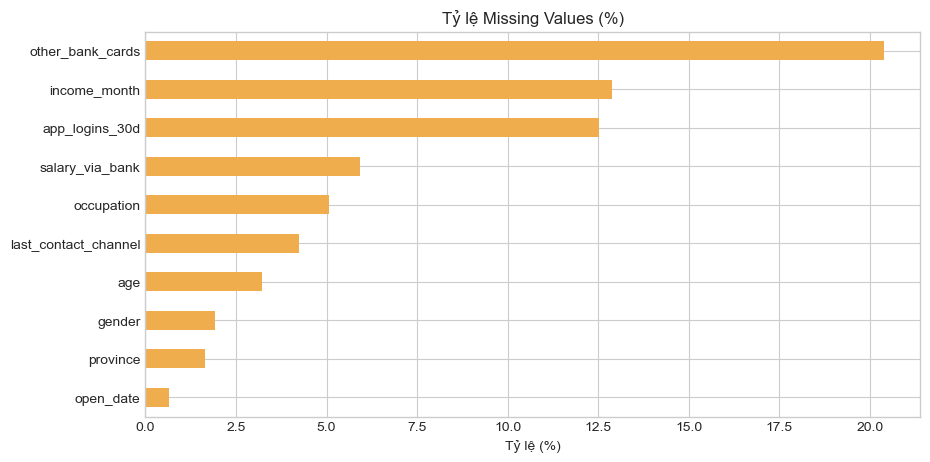

In [5]:
missing_df = audit_missing_values(df_clean)
print("Danh sách cột bị khuyết thiếu:")
display(missing_df)

fig, ax = plt.subplots(figsize=(10, 5))
missing_df['missing_pct'].plot(kind='barh', color='#f0ad4e', ax=ax)
ax.set_title("Tỷ lệ Missing Values (%)")
ax.set_xlabel("Tỷ lệ (%)")
plt.gca().invert_yaxis()
plt.show()

## 5. Chuẩn hóa Phân loại (Categorical Normalization)

In [6]:
cat_audit = audit_categories(df_clean)
for col, info in cat_audit.items():
    print(f"Cột '{col}': raw_unique={info['raw_unique_count']} -> normalized_unique={info['normalized_unique_count']}")
    print(f"  Top values: {list(info['top_values'].keys())[:5]}")

Cột 'gender': raw_unique=9 -> normalized_unique=6
  Top values: ['F', 'M', 'female', 'male', 'F ']
Cột 'province': raw_unique=42 -> normalized_unique=37
  Top values: ['TP.HCM', 'Hà Nội', 'Hải Phòng', 'Đà Nẵng', 'Bình Dương']
Cột 'occupation': raw_unique=16 -> normalized_unique=9
  Top values: ['salaried', 'self_employed', 'civil_servant', 'other', 'retired']
Cột 'card_type': raw_unique=4 -> normalized_unique=4
  Top values: ['Cashback', 'Classic', 'Gold', 'Platinum']
Cột 'salary_via_bank': raw_unique=3 -> normalized_unique=2
  Top values: ['N', 'Y', 'nan']
Cột 'last_contact_channel': raw_unique=5 -> normalized_unique=4
  Top values: ['app', 'none', 'branch', 'hotline', 'nan']
Cột 'bank_code': raw_unique=1 -> normalized_unique=1
  Top values: ['VB01']
Cột 'currency': raw_unique=2 -> normalized_unique=1
  Top values: ['VND', 'vnd']


## 6. Kiểm tra Giá trị Dị biệt & Sai lệch Đơn vị (Outliers & Unit Discrepancy)

In [7]:
outliers_audit = audit_outliers_and_sentinels(df_clean)
print("1. Age Audit:", outliers_audit['age'])
print("2. Income Month Audit:", outliers_audit['income_month'])
print("3. Credit Limit Audit:", outliers_audit['credit_limit'])
print("4. Utilization 6m Audit:", outliers_audit['utilization_6m'])
print("5. Txn Amount 3m Audit:", outliers_audit['txn_amount_3m'])

1. Age Audit: {'nulls': 388, 'min': 0.0, 'max': 999.0, 'sentinel_999_count': 9, 'under_18_count': 29, 'over_100_count': 40}
2. Income Month Audit: {'nulls': 1547, 'median': 17.7, 'max': 50500000.0, 'recorded_in_raw_vnd_count': 106, 'raw_vnd_sample_values': [31000000.0, 18000000.0, 14800000.0, 10000000.0, 9500000.0]}
3. Credit Limit Audit: {'nulls': 0, 'median': 40.0, 'max': 385000000.0, 'recorded_in_raw_vnd_count': 245, 'raw_vnd_sample_values': [35000000.0, 25000000.0, 55000000.0, 40000000.0, 25000000.0]}
4. Utilization 6m Audit: {'nulls': 0, 'min': -1.0, 'max': 15.0, 'negative_count': 40, 'greater_than_1_count': 45}
5. Txn Amount 3m Audit: {'nulls': 0, 'min': -2.99, 'max': 462.81, 'negative_count': 169, 'negative_min': -2.99, 'negative_max': -0.12}


## 7. Phân tích Ngày mở thẻ & Ranh giới Snapshot (Date Audit)

In [8]:
date_audit = audit_dates(df_clean, snapshot_date=SNAPSHOT_DATE)
print("Kết quả Date Audit:")
for k, v in date_audit['open_date'].items():
    print(f"  - {k}: {v}")

assert date_audit['open_date']['dates_after_snapshot'] == 0, "Không được có ngày sau snapshot!"

Kết quả Date Audit:
  - total_nulls: 78
  - parsed_nulls: 78
  - unparseable_count: 0
  - min_open_date: 2011-06-21
  - max_open_date: 2026-06-12
  - snapshot_date: 2026-06-30
  - dates_after_snapshot: 0


## 8. Xuất Dữ liệu Đã Làm Sạch (Cleaned Dataset)

In [9]:
df_final_clean = clean_raw_dataframe(df_clean, fix_unit_inconsistencies=True)
print(f"Dữ liệu sạch hoàn tất: {df_final_clean.shape}")
print("Thống kê thu nhập sau chuẩn hóa đơn vị (triệu VNĐ):")
print(df_final_clean['income_month'].describe())
print("\nThống kê hạn mức tín dụng sau chuẩn hóa đơn vị (triệu VNĐ):")
print(df_final_clean['credit_limit'].describe())

Dữ liệu sạch hoàn tất: (12000, 25)
Thống kê thu nhập sau chuẩn hóa đơn vị (triệu VNĐ):
count    10453.000000
mean        20.549785
std         13.432974
min          1.000000
25%         11.700000
50%         17.500000
75%         25.800000
max        220.900000
Name: income_month, dtype: float64

Thống kê hạn mức tín dụng sau chuẩn hóa đơn vị (triệu VNĐ):
count    12000.000000
mean        55.109583
std         52.062496
min         10.000000
25%         25.000000
50%         40.000000
75%         65.000000
max        790.000000
Name: credit_limit, dtype: float64
